# 02 · Análise: P&L e perguntas de negócio

Lê apenas a camada **gold** (e a silver quando a pergunta exige granularidade diária). Duas visões:

- **Oficial**: lançamentos registrados até o `official_cutoff_at` do mês. É o número de Finance.
- **Atualizada**: tudo o que chegou até B02 (20/09/2026). É a melhor leitura de performance, mas não reabre o fechamento.

Gross Profit não inclui a conta `Z900` (sem mapeamento), que aparece à parte como `unmapped`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import functions as fn

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
fn.set_chart_style()

fact_pnl = fn.load_gold("fact_pnl")
fact_tpv = fn.load_gold("fact_tpv")
merchants = fn.load_gold("dim_merchants")
calendar = fn.load_gold("dim_close_calendar")

CLOSED = fn.closed_periods(calendar)
LAST_CLOSED = CLOSED[-1]
OPEN_PERIOD = pd.Timestamp("2026-09-01")

USD_COLS = ["tpv", "net_revenue", "cost_of_sales", "direct_costs", "indirect_costs", "gross_profit", "unmapped"]
PCT_COLS = ["take_rate", "gp_margin", "gp_over_tpv"]

monthly = fn.pnl_summary(fact_pnl, fact_tpv, ["period"], view="official").loc[CLOSED]
monthly_updated = fn.pnl_summary(fact_pnl, fact_tpv, ["period"], view="updated")

## P&L gerencial mensal (visão oficial, USD)

In [2]:
pnl_table = monthly[USD_COLS + PCT_COLS].copy()
pnl_table.index = pnl_table.index.map(fn.format_month)
fn.format_table(pnl_table, usd=USD_COLS, pct=PCT_COLS)

,tpv,net_revenue,cost_of_sales,direct_costs,indirect_costs,gross_profit,unmapped,take_rate,gp_margin,gp_over_tpv
period,,,,,,,,,,
set/24,"$125,809","$4,549","$-2,493","$-1,773",$-720,"$2,056",$0,3.62%,45.21%,1.63%
out/24,"$135,066","$4,792","$-2,685","$-1,929",$-756,"$2,107",$0,3.55%,43.97%,1.56%
nov/24,"$170,382","$6,017","$-3,255","$-2,463",$-792,"$2,762",$0,3.53%,45.91%,1.62%
dez/24,"$171,819","$6,091","$-3,350","$-2,522",$-828,"$2,741",$0,3.55%,45.00%,1.60%
jan/25,"$152,356","$5,277","$-3,130","$-2,266",$-864,"$2,147",$0,3.46%,40.68%,1.41%
fev/25,"$155,421","$5,409","$-3,246","$-2,346",$-900,"$2,163",$0,3.48%,39.98%,1.39%
mar/25,"$166,354","$5,666","$-3,499","$-2,563",$-936,"$2,167",$0,3.41%,38.25%,1.30%
abr/25,"$174,744","$5,968","$-3,686","$-2,714",$-972,"$2,282",$0,3.42%,38.24%,1.31%
mai/25,"$182,999","$6,176","$-3,894","$-2,886","$-1,008","$2,282",$0,3.37%,36.94%,1.25%


In [3]:
totals = pd.DataFrame(
    {
        "12m até ago/25": monthly.loc[CLOSED[:12], USD_COLS].sum(),
        "12m até ago/26": monthly.loc[CLOSED[12:], USD_COLS].sum(),
    }
).T
totals["take_rate"] = totals["net_revenue"] / totals["tpv"]
totals["gp_margin"] = totals["gross_profit"] / totals["net_revenue"]
totals["gp_over_tpv"] = totals["gross_profit"] / totals["tpv"]
totals.loc["variação"] = totals.iloc[1] / totals.iloc[0] - 1
fn.format_table(totals.iloc[:2], usd=USD_COLS, pct=PCT_COLS)

,tpv,net_revenue,cost_of_sales,direct_costs,indirect_costs,gross_profit,unmapped,take_rate,gp_margin,gp_over_tpv
12m até ago/25,"$2,012,409","$69,075","$-41,862","$-30,846","$-11,016","$27,213",$0,3.43%,39.40%,1.35%
12m até ago/26,"$2,978,753","$93,042","$-72,487","$-53,118","$-19,369","$20,555","$-3,600",3.12%,22.09%,0.69%


### Visão geral: o volume cresce, o spread encolhe

A cada US$ 100 processados, a OrionPay recebia US$ 3,62 em receita líquida em set/24 e US$ 2,77 em ago/26. No mesmo período, o custo de venda por US$ 100 subiu de US$ 1,98 para US$ 2,80. O Gross Profit por TPV saiu de 1,6% para zero.

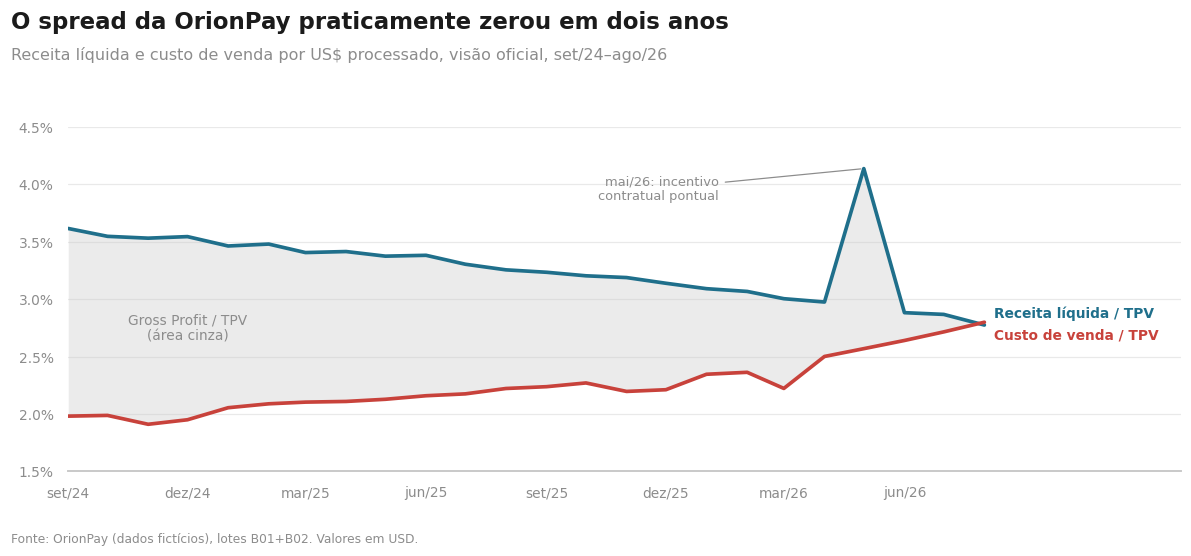

In [4]:
unit = monthly.assign(cost_rate=-monthly["cost_of_sales"] / monthly["tpv"])

fig, ax = plt.subplots(figsize=(11, 5.2))
x = unit.index
ax.plot(x, unit["take_rate"], color=fn.ACCENT_2, lw=2.4)
ax.plot(x, unit["cost_rate"], color=fn.ACCENT, lw=2.4)
ax.fill_between(x, unit["cost_rate"], unit["take_rate"], color=fn.NEUTRAL, alpha=0.35, lw=0)
fn.label_line_end(ax, x[-1], unit["take_rate"].iloc[-1], "Receita líquida / TPV", fn.ACCENT_2, offset=8)
fn.label_line_end(ax, x[-1], unit["cost_rate"].iloc[-1], "Custo de venda / TPV", fn.ACCENT, offset=-8)
ax.annotate(
    "Gross Profit / TPV\n(área cinza)",
    xy=(x[3], (unit["take_rate"].iloc[3] + unit["cost_rate"].iloc[3]) / 2),
    ha="center", va="center", fontsize=9, color=fn.MUTED,
)
may_26 = pd.Timestamp("2026-05-01")
ax.annotate("mai/26: incentivo\ncontratual pontual", xy=(may_26, unit.loc[may_26, "take_rate"]), xytext=(-95, -4),
            textcoords="offset points", fontsize=8.5, color=fn.MUTED, ha="right", va="top",
            arrowprops=dict(arrowstyle="-", color=fn.MUTED, lw=0.8))
ax.yaxis.set_major_formatter(fn.pct_formatter(1))
ax.set_ylim(0.015, 0.045)
ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=150))
ax.set_xticks(x[::3], [fn.format_month(p) for p in x[::3]])
fn.chart_titles(
    fig,
    "O spread da OrionPay praticamente zerou em dois anos",
    "Receita líquida e custo de venda por US$ processado, visão oficial, set/24–ago/26",
)
fn.save_chart(fig, "00_spread_unitario")
plt.show()

O que explica o aperto (detalhado nas perguntas 2 e 3):

- **Mix**: o Brasil passou de 32% para 74% do TPV, e é o país com menor take rate. PAY_OUT passou de 14% para 44% do TPV, com take rate menor e custo maior que PAY_IN.
- **Preço**: dentro de cada país o take rate caiu, sobretudo no Brasil (3,13% → 2,44%).
- **Custo**: o custo direto por TPV subiu em todos os países, e o custo compartilhado (C200) cresce cerca de 3% ao mês, independente do volume.

In [5]:
by_country = fn.pnl_summary(fact_pnl, fact_tpv, ["period", "country_code"], view="official")
by_country = by_country[by_country.index.get_level_values("period").isin(CLOSED)]
share = (by_country["tpv"] / by_country.groupby(level="period")["tpv"].transform("sum")).unstack()

first, last = by_country.xs(CLOSED[0]), by_country.xs(LAST_CLOSED)
first_share, last_share = share.loc[CLOSED[0]], share.loc[LAST_CLOSED]
take_rate_change = last["net_revenue"].sum() / last["tpv"].sum() - first["net_revenue"].sum() / first["tpv"].sum()
rate_effect = ((last["take_rate"] - first["take_rate"]) * last_share).sum()
mix_effect = ((last_share - first_share) * first["take_rate"]).sum()

pd.Series(
    {"variação do take rate (p.p.)": take_rate_change * 100, "efeito preço (p.p.)": rate_effect * 100, "efeito mix de países (p.p.)": mix_effect * 100}
).round(2).to_frame("set/24 → ago/26")

,set/24 → ago/26
variação do take rate (p.p.),-0.84
efeito preço (p.p.),-0.54
efeito mix de países (p.p.),-0.30


---
## Pergunta 1 · Qual mês completo teve o maior Gross Profit?

Três leituras levam a três respostas diferentes, e é aí que mora a resposta:

| Leitura | Mês | GP | Por quê |
|---|---|---|---|
| Dados crus (câmbio COP sem correção) | mar/25 | US$ 5,7k | **Artefato**: taxa COP 10× maior infla receita e custo de Colômbia |
| Visão oficial tratada | **mai/26** | **US$ 4,0k** | **Evento pontual**: incentivo contratual R120 de US$ 3,0k (MX, sem merchant) |
| Recorrente (sem eventos pontuais) | nov/24 | US$ 2,8k | **Contribuição observada**: TPV +26% contra out/24 com spread ainda saudável |

A resposta oficial é **mai/26**, mas sem o incentivo o mês teria GP de US$ 989, um dos piores da série. O melhor mês operacional foi **nov/24**.

In [6]:
ONE_OFF = (fact_pnl["source_account"] == "R120") | (
    (fact_pnl["source_account"] == "C300") & (fact_pnl["period"] == pd.Timestamp("2026-03-01"))
)

readings = pd.DataFrame(
    {
        "dados_crus_fx": fn.pnl_summary(fact_pnl, fact_tpv, ["period"], amount_col="amount_usd_original_fx", tpv_col="tpv_usd_original_fx")["gross_profit"],
        "oficial": monthly["gross_profit"],
        "recorrente": fn.pnl_summary(fact_pnl[~ONE_OFF], fact_tpv, ["period"])["gross_profit"],
    }
).loc[CLOSED]

summary = pd.DataFrame({"mês": readings.idxmax().map(fn.format_month), "gross_profit": readings.max()})
summary

,mês,gross_profit
dados_crus_fx,mar/25,5703.56
oficial,mai/26,3989.46
recorrente,nov/24,2762.36


In [7]:
top5 = readings.sort_values("oficial", ascending=False).head(5).copy()
top5.index = top5.index.map(fn.format_month)
fn.format_table(top5, usd=list(top5.columns))

,dados_crus_fx,oficial,recorrente
period,,,
mai/26,"$3,989","$3,989",$989
nov/24,"$2,762","$2,762","$2,762"
dez/24,"$2,741","$2,741","$2,741"
nov/25,"$2,566","$2,566","$2,566"
dez/25,"$2,517","$2,517","$2,517"


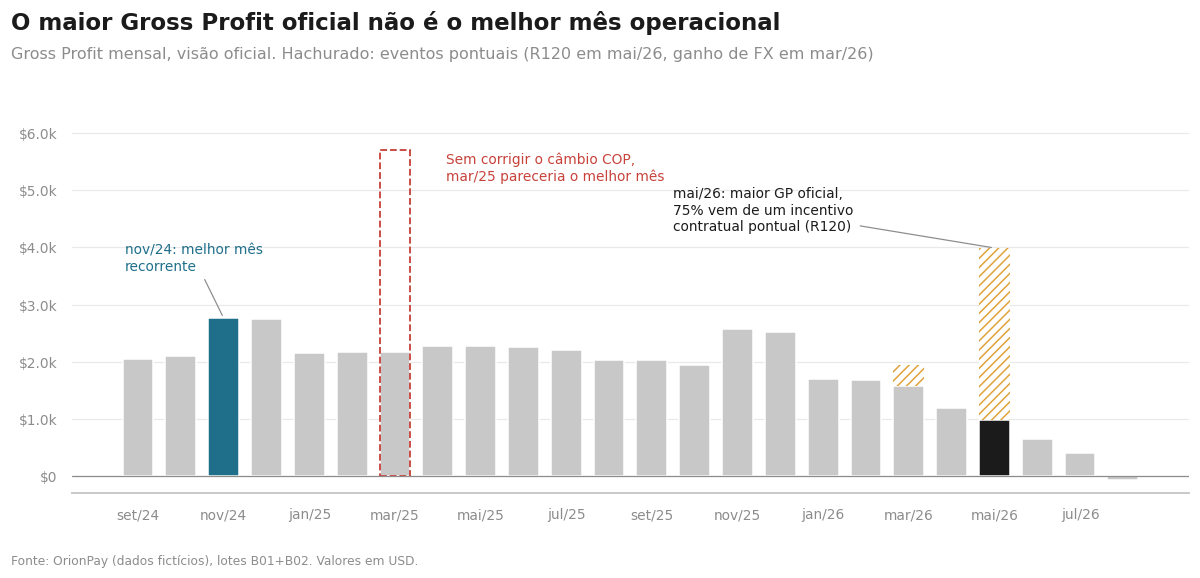

In [8]:
one_off_by_period = fn.select_view(fact_pnl[ONE_OFF], "official").groupby("period")["amount_usd"].sum().reindex(CLOSED, fill_value=0)
recurring = readings["recorrente"]
best_official, best_recurring = readings["oficial"].idxmax(), recurring.idxmax()
raw_fx_period = pd.Timestamp("2025-03-01")

fig, ax = plt.subplots(figsize=(11, 5.4))
positions = np.arange(len(CLOSED))
colors = [fn.ACCENT_2 if p == best_recurring else (fn.INK if p == best_official else fn.NEUTRAL) for p in CLOSED]
ax.bar(positions, recurring.values, color=colors, width=0.72)
ax.bar(positions, one_off_by_period.values, bottom=recurring.values, color="white", edgecolor=fn.ACCENT_3, hatch="////", width=0.72, lw=0)

raw_index = CLOSED.index(raw_fx_period)
ax.bar(raw_index, readings.loc[raw_fx_period, "dados_crus_fx"], fill=False, edgecolor=fn.ACCENT, ls="--", lw=1.2, width=0.72)
ax.annotate("Sem corrigir o câmbio COP,\nmar/25 pareceria o melhor mês", xy=(raw_index, readings.loc[raw_fx_period, "dados_crus_fx"]),
            xytext=(raw_index + 1.2, 5400), fontsize=9, color=fn.ACCENT, va="center")
best_index = CLOSED.index(best_official)
ax.annotate("mai/26: maior GP oficial,\n75% vem de um incentivo\ncontratual pontual (R120)", xy=(best_index, readings.loc[best_official, "oficial"]),
            xytext=(best_index - 7.5, 4300), fontsize=9, color=fn.INK, arrowprops=dict(arrowstyle="-", color=fn.MUTED, lw=0.8))
rec_index = CLOSED.index(best_recurring)
ax.annotate("nov/24: melhor mês\nrecorrente", xy=(rec_index, recurring.loc[best_recurring]),
            xytext=(rec_index - 2.3, 3600), fontsize=9, color=fn.ACCENT_2, arrowprops=dict(arrowstyle="-", color=fn.MUTED, lw=0.8))
ax.axhline(0, color=fn.MUTED, lw=0.8)
ax.set_xticks(positions[::2], [fn.format_month(p) for p in CLOSED[::2]])
ax.yaxis.set_major_formatter(fn.usd_formatter(1))
ax.set_ylim(-300, 6200)
fn.chart_titles(fig, "O maior Gross Profit oficial não é o melhor mês operacional",
                "Gross Profit mensal, visão oficial. Hachurado: eventos pontuais (R120 em mai/26, ganho de FX em mar/26)")
fn.save_chart(fig, "01_gp_mensal")
plt.show()

### O que explica a variação

Ponte de GP por linha da P&L contra o mês anterior, para o maior mês oficial e para o melhor mês recorrente.

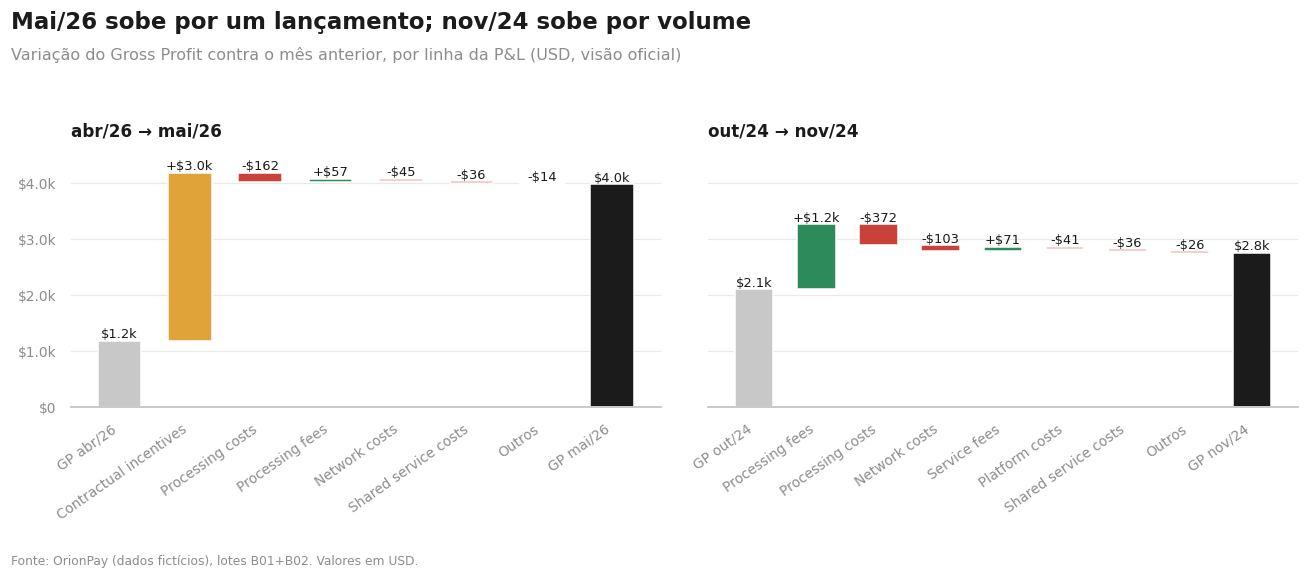

In [9]:
def bridge(current: pd.Timestamp, previous: pd.Timestamp) -> pd.Series:
    scope = fn.select_view(fact_pnl, "official")
    scope = scope[scope["is_mapped"] & scope["period"].isin([previous, current])]
    by_line = scope.pivot_table(index="pl_line", columns="period", values="amount_usd", aggfunc="sum").fillna(0)
    delta = (by_line[current] - by_line[previous]).round(2)
    return delta[delta.abs() >= 1].sort_values(key=lambda s: -s.abs())


fig, axes = plt.subplots(1, 2, figsize=(12, 5.4), sharey=True)
for ax, (current, previous) in zip(axes, [(best_official, pd.Timestamp("2026-04-01")), (best_recurring, pd.Timestamp("2024-10-01"))]):
    steps = bridge(current, previous)
    fn.waterfall(ax, (f"GP {fn.format_month(previous)}", readings.loc[previous, "oficial"]), steps, f"GP {fn.format_month(current)}", highlight="Contractual incentives")
    ax.set_title(f"{fn.format_month(previous)} → {fn.format_month(current)}", loc="left", fontsize=11, color=fn.INK, fontweight="bold")
fn.chart_titles(fig, "Mai/26 sobe por um lançamento; nov/24 sobe por volume",
                "Variação do Gross Profit contra o mês anterior, por linha da P&L (USD, visão oficial)")
fn.save_chart(fig, "01b_pontes_gp")
plt.show()

In [10]:
payments = pd.read_csv(fn.SILVER_DIR / "payment_events.csv", parse_dates=["event_at"])
payments = payments[payments["is_tpv"]]
payments["period"] = pd.to_datetime(payments["period"])

def volume_profile(periods: list[pd.Timestamp]) -> pd.DataFrame:
    scoped = payments[payments["period"].isin(periods)]
    profile = scoped.groupby("period").agg(pagamentos=("event_id", "size"), tpv=("amount_usd", "sum"))
    profile["ticket_medio"] = profile["tpv"] / profile["pagamentos"]
    weekly = scoped.assign(semana=(scoped["event_at"].dt.day - 1) // 7 + 1).pivot_table(index="period", columns="semana", values="amount_usd", aggfunc="sum")
    weekly.columns = [f"tpv_semana_{c}" for c in weekly.columns]
    return profile.join(weekly).rename(index=fn.format_month)

volume_profile([pd.Timestamp("2024-10-01"), pd.Timestamp("2024-11-01"), pd.Timestamp("2025-10-01"), pd.Timestamp("2025-11-01")]).round(0)

,pagamentos,tpv,ticket_medio,tpv_semana_1,tpv_semana_2,tpv_semana_3,tpv_semana_4,tpv_semana_5
period,,,,,,,,
out/24,470,135066.0,287.0,33009.0,28542.0,30690.0,30226.0,12599.0
nov/24,587,170382.0,290.0,42291.0,40434.0,38476.0,37790.0,11391.0
out/25,696,207587.0,298.0,49288.0,44589.0,45914.0,49995.0,17801.0
nov/25,858,258688.0,302.0,58389.0,61123.0,61936.0,59411.0,17829.0


**Leitura para a pergunta 1**

- **Contribuição observada (mai/26 vs abr/26)**: o incentivo contratual R120 (+US$ 3,0k) responde por praticamente toda a variação. Receitas transacionais sobem US$ 64 e custos sobem US$ 263, ou seja, a operação piorou no mês.
- **Evento pontual**: o R120 é um único lançamento, sem merchant nem pagamento, no México. Como é uma linha de `REVENUE_ADJUSTMENTS` com sinal positivo, vale confirmar com Finance se é de fato um incentivo recebido, e não um crédito concedido com sinal invertido. Se o sinal estiver errado, mai/26 passa a ter GP de -US$ 2,0k e vira o pior mês da série.
- **Contribuição observada (nov/24 vs out/24)**: +US$ 1.164 em processing fees com take rate estável. O ganho vem de mais pagamentos (+25%), não de ticket maior (estável em ~US$ 290), e o crescimento está distribuído por todos os países.
- **Hipótese causal (não comprovada)**: sazonalidade de fim de ano. Nov e dez são os dois maiores meses em 2024 e 2025, e o volume cai em janeiro. Mas o aumento não se concentra na semana da Black Friday, é um degrau ao longo do mês inteiro. Isso é compatível também com entrada de clientes ou campanha comercial. Para confirmar, seria preciso olhar a base de merchants ativos e o calendário comercial.
- **Visão usada**: oficial, com câmbio corrigido e duplicados removidos.

---
## Pergunta 2 · Último período fechado (ago/26): países, merchants e rentabilidade

In [11]:
aug_pnl = fact_pnl[fact_pnl["period"] == LAST_CLOSED]
aug_tpv = fact_tpv[fact_tpv["period"] == LAST_CLOSED]

countries_aug = fn.pnl_summary(aug_pnl, aug_tpv, ["country_code"], view="official").sort_values("net_revenue", ascending=False)
countries_aug["share_tpv"] = countries_aug["tpv"] / countries_aug["tpv"].sum()
countries_aug["share_net_revenue"] = countries_aug["net_revenue"] / countries_aug["net_revenue"].sum()
fn.format_table(
    countries_aug[["tpv", "share_tpv", "net_revenue", "share_net_revenue", "take_rate", "gross_profit", "gp_over_tpv", "gp_margin", "unmapped"]],
    usd=["tpv", "net_revenue", "gross_profit", "unmapped"],
    pct=["share_tpv", "share_net_revenue", "take_rate", "gp_over_tpv", "gp_margin"],
)

,tpv,share_tpv,net_revenue,share_net_revenue,take_rate,gross_profit,gp_over_tpv,gp_margin,unmapped
country_code,,,,,,,,,
BR,"$206,241",73.65%,"$5,024",64.66%,2.44%,$-295,-0.14%,-5.87%,$0
MX,"$28,046",10.02%,"$1,094",14.08%,3.90%,$191,0.68%,17.41%,$-600
CO,"$23,061",8.24%,$852,10.97%,3.70%,$16,0.07%,1.88%,$-600
CL,"$22,672",8.10%,$800,10.29%,3.53%,$19,0.08%,2.37%,$0


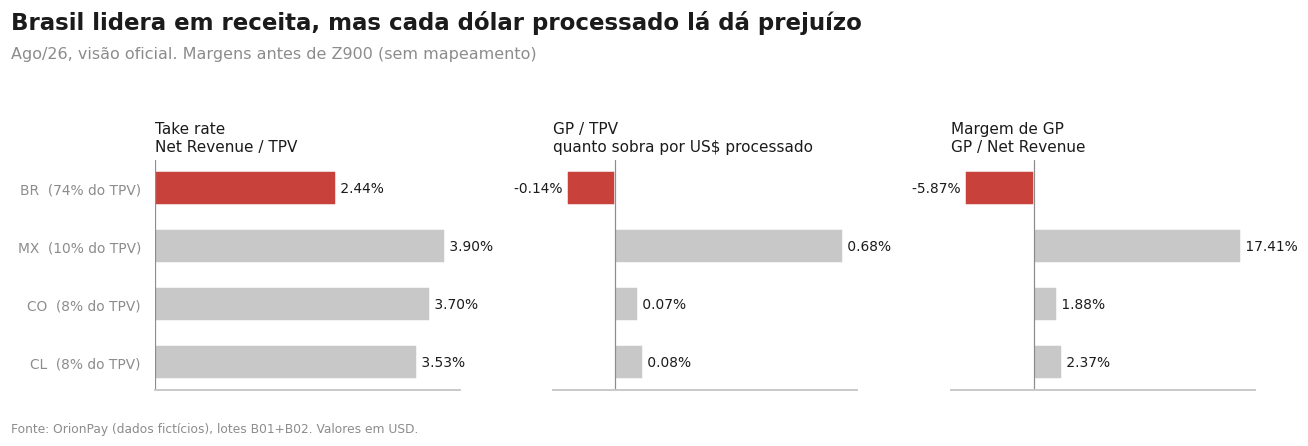

In [12]:
metrics = [("take_rate", "Take rate\nNet Revenue / TPV"), ("gp_over_tpv", "GP / TPV\nquanto sobra por US$ processado"), ("gp_margin", "Margem de GP\nGP / Net Revenue")]
order = countries_aug.sort_values("tpv").index

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2), sharey=True)
for ax, (col, title) in zip(axes, metrics):
    values = countries_aug.loc[order, col]
    colors = [fn.ACCENT if c == "BR" else fn.NEUTRAL for c in order]
    ax.barh(order, values, color=colors, height=0.6)
    for y, v in enumerate(values):
        ax.text(v, y, f" {v:.2%}" if v >= 0 else f"{v:.2%} ", va="center", ha="left" if v >= 0 else "right", fontsize=9, color=fn.INK)
    ax.axvline(0, color=fn.MUTED, lw=0.8)
    ax.set_title(title, loc="left", fontsize=10, color=fn.INK)
    ax.xaxis.set_visible(False)
    ax.grid(False)
axes[0].set_yticks(range(len(order)), [f"{c}  ({countries_aug.loc[c, 'share_tpv']:.0%} do TPV)" for c in order])
fn.chart_titles(fig, "Brasil lidera em receita, mas cada dólar processado lá dá prejuízo",
                "Ago/26, visão oficial. Margens antes de Z900 (sem mapeamento)")
fn.save_chart(fig, "02_paises_ago26")
plt.show()

In [13]:
merchants_aug = fn.pnl_summary(aug_pnl, aug_tpv, ["merchant_id"], view="official")
br_share = aug_tpv.pivot_table(index="merchant_id", columns="country_code", values="tpv_usd", aggfunc="sum").fillna(0)
merchants_aug["share_tpv_brasil"] = (br_share["BR"] / br_share.sum(axis=1)).reindex(merchants_aug.index)
merchants_aug = merchants_aug.join(merchants.set_index("merchant_id")[["merchant_name", "segment", "vertical"]])
merchants_aug["countries"] = aug_tpv.groupby("merchant_id")["country_code"].nunique()

attributed = merchants_aug.drop(index=fn.UNATTRIBUTED).sort_values("gross_profit", ascending=False)
cols = ["merchant_name", "segment", "countries", "tpv", "net_revenue", "gross_profit", "take_rate", "gp_over_tpv", "gp_margin", "share_tpv_brasil"]
fn.format_table(attributed[cols].head(10), usd=["tpv", "net_revenue", "gross_profit"], pct=["take_rate", "gp_over_tpv", "gp_margin", "share_tpv_brasil"])

,merchant_name,segment,countries,tpv,net_revenue,gross_profit,take_rate,gp_over_tpv,gp_margin,share_tpv_brasil
merchant_id,,,,,,,,,,
M6205,Orion Horizonte,SCALE,4.000000,"$10,280",$317,$94,3.08%,0.92%,29.80%,49.57%
M3787,Orion Rubi,SCALE,4.000000,"$12,970",$367,$84,2.83%,0.65%,22.86%,63.82%
M9382,Orion Wadi,SCALE,1.000000,"$3,942",$155,$82,3.92%,2.08%,53.00%,0.00%
M8608,Orion Delta,EMERGING,3.000000,"$9,211",$278,$76,3.02%,0.83%,27.52%,54.67%
M2066,Orion Eclipse,CORE,3.000000,"$9,621",$283,$71,2.94%,0.74%,25.21%,68.41%
M4051,Orion Brisa,SCALE,4.000000,"$9,999",$285,$65,2.86%,0.65%,22.61%,64.46%
M4248,Orion Fênix,SCALE,3.000000,"$9,485",$273,$64,2.88%,0.67%,23.27%,63.83%
M6117,Orion Boreal,SCALE,1.000000,"$3,333",$120,$62,3.59%,1.87%,52.10%,0.00%
M5351,Orion Prisma,CORE,4.000000,"$22,355",$581,$62,2.60%,0.28%,10.62%,88.14%


In [14]:
reconciliation = pd.Series(
    {
        "GP atribuído a merchants": attributed["gross_profit"].sum(),
        "GP não atribuível (C200 shared services)": merchants_aug.loc[fn.UNATTRIBUTED, "gross_profit"],
        "GP total oficial ago/26": monthly.loc[LAST_CLOSED, "gross_profit"],
        "Z900 sem mapeamento (fora do GP)": merchants_aug.loc[fn.UNATTRIBUTED, "unmapped"],
    }
).round(2)
reconciliation.to_frame("USD")

,USD
GP atribuído a merchants,1478.86
GP não atribuível (C200 shared services),-1548.00
GP total oficial ago/26,-69.14
Z900 sem mapeamento (fora do GP),-1200.00


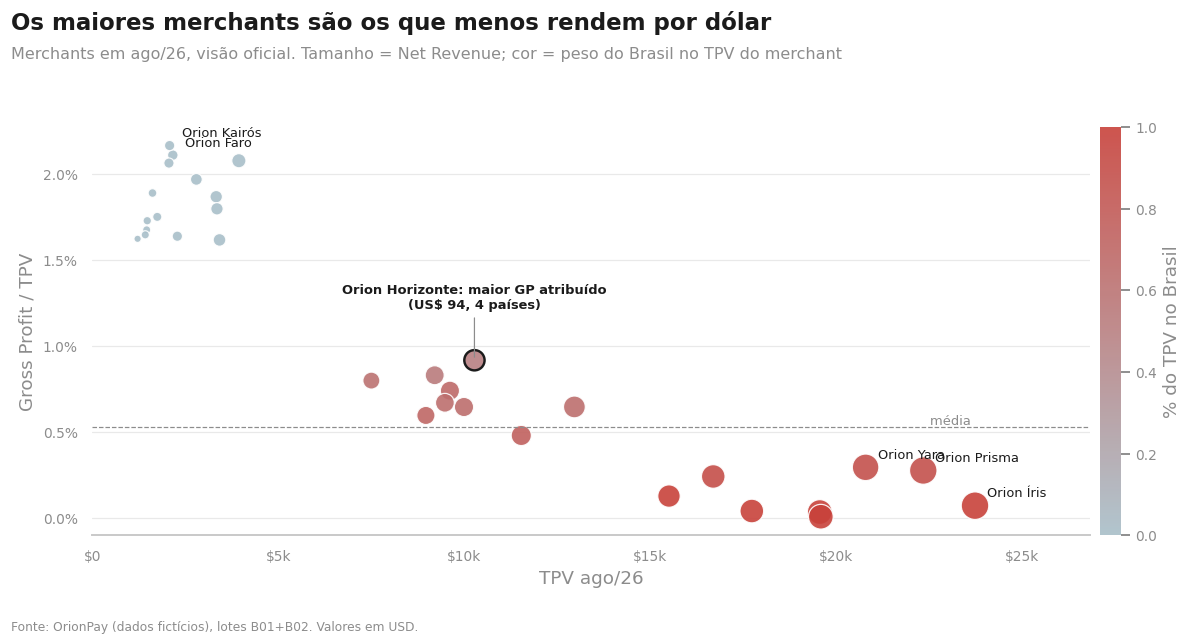

In [15]:
from matplotlib.colors import LinearSegmentedColormap

brazil_cmap = LinearSegmentedColormap.from_list("brazil", ["#a9bfc9", fn.ACCENT])
to_label = set(attributed.nlargest(3, "tpv").index) | set(attributed.nlargest(2, "gp_over_tpv").index)
top_gp = attributed.index[0]

fig, ax = plt.subplots(figsize=(11, 6))
scatter = ax.scatter(
    attributed["tpv"], attributed["gp_over_tpv"], s=attributed["net_revenue"] / 1.8,
    c=attributed["share_tpv_brasil"], cmap=brazil_cmap, vmin=0, vmax=1, alpha=0.9, edgecolor="white", lw=0.8,
)
ax.scatter(attributed.loc[top_gp, "tpv"], attributed.loc[top_gp, "gp_over_tpv"], s=attributed.loc[top_gp, "net_revenue"] / 1.8,
           facecolor="none", edgecolor=fn.INK, lw=1.6)
for merchant_id in to_label:
    row = attributed.loc[merchant_id]
    ax.annotate(row["merchant_name"], (row["tpv"], row["gp_over_tpv"]), xytext=(8, 6), textcoords="offset points", fontsize=8.5, color=fn.INK)
ax.annotate(f"{attributed.loc[top_gp, 'merchant_name']}: maior GP atribuído\n(US$ {attributed.loc[top_gp, 'gross_profit']:,.0f}, 4 países)",
            (attributed.loc[top_gp, "tpv"], attributed.loc[top_gp, "gp_over_tpv"]), xytext=(0, 34), textcoords="offset points",
            fontsize=8.5, color=fn.INK, fontweight="bold", ha="center", arrowprops=dict(arrowstyle="-", color=fn.MUTED, lw=0.8))
ax.axhline(attributed["gross_profit"].sum() / attributed["tpv"].sum(), color=fn.MUTED, lw=0.8, ls="--")
ax.text(attributed["tpv"].max(), attributed["gross_profit"].sum() / attributed["tpv"].sum(), "média ", ha="right", va="bottom", fontsize=8.5, color=fn.MUTED)
ax.set_xlim(0, attributed["tpv"].max() * 1.13)
ax.xaxis.set_major_formatter(fn.usd_formatter(0))
ax.yaxis.set_major_formatter(fn.pct_formatter(1))
ax.set_xlabel("TPV ago/26")
ax.set_ylabel("Gross Profit / TPV")
cbar = fig.colorbar(scatter, ax=ax, pad=0.01, fraction=0.03)
cbar.set_label("% do TPV no Brasil", color=fn.MUTED)
cbar.outline.set_visible(False)
fn.chart_titles(fig, "Os maiores merchants são os que menos rendem por dólar",
                "Merchants em ago/26, visão oficial. Tamanho = Net Revenue; cor = peso do Brasil no TPV do merchant")
fn.save_chart(fig, "02b_merchants_volume_vs_rentabilidade")
plt.show()

In [16]:
correlation = attributed[["tpv", "gp_over_tpv", "share_tpv_brasil"]].corr(method="spearman").round(2)
correlation

,tpv,gp_over_tpv,share_tpv_brasil
tpv,1.00,-0.83,0.91
gp_over_tpv,-0.83,1.00,-0.94
share_tpv_brasil,0.91,-0.94,1.00


**Leitura para a pergunta 2**

- **País líder em Net Revenue**: Brasil, com US$ 5,0k (65% da receita líquida). Isso representa **2,44% do TPV brasileiro**, o menor take rate entre os quatro países (MX: 3,90%).
- **Merchant com maior GP atribuído** (somando os 4 países em que opera): **Orion Horizonte (M6205)**, com US$ 94 de GP sobre US$ 10,3k de TPV (GP/TPV de 0,92%). Ele é só o 11º em volume.
- **Volume sem rentabilidade**: o Brasil tem 74% do TPV e GP negativo (-US$ 295). Os 5 maiores merchants em TPV somam 38% do volume e apenas 10% do GP atribuído. Orion Íris, o maior de todos, gera US$ 17 de GP sobre US$ 23,7k de TPV. A correlação (Spearman) entre o peso do Brasil no TPV do merchant e o GP/TPV é de -0,94: o problema é o país, não o merchant.
- **As três métricas respondem a perguntas diferentes**: take rate mede preço (quanto cobramos por US$ processado); GP/TPV mede quanto sobra por US$ processado depois do custo; margem de GP mede quanto da receita vira lucro bruto. O Brasil tem take rate de 2,4% mas GP/TPV negativo, então volume brasileiro adicional piora o resultado.
- **Valores não atribuíveis a merchants**: Shared service costs (C200, -US$ 1.548) entra no GP total mas não no de nenhum merchant. Compliance (Z900, -US$ 1.200 em ago/26) não tem mapeamento e fica fora do GP. Por isso a soma do GP dos merchants (US$ 1.479) é maior que o GP total (-US$ 69).

---
## Pergunta 3 · Custos diretos por produto

In [17]:
entries_official = fn.select_view(fact_pnl, "official")
entries_official = entries_official[entries_official["period"].isin(CLOSED)]
COST_ACCOUNTS = ["C100", "C110", "C120", "C190", "C300"]
costs = entries_official[entries_official["source_account"].isin(COST_ACCOUNTS)].copy()
costs["como_reportado"] = np.where(costs["pl_subgroup"] == "DIRECT_COSTS", costs["amount_usd"], 0.0)
costs["comparavel"] = costs["amount_usd"]

tpv_by_product = fact_tpv[fact_tpv["period"].isin(CLOSED)].pivot_table(index="period", columns="product", values="tpv_usd", aggfunc="sum")
direct_by_product = costs.pivot_table(index="period", columns="product", values=["como_reportado", "comparavel"], aggfunc="sum").fillna(0)
cost_rate = {
    basis: -direct_by_product[basis][["PAY_IN", "PAY_OUT"]] / tpv_by_product[["PAY_IN", "PAY_OUT"]]
    for basis in ["como_reportado", "comparavel"]
}

year_label = np.where(costs["period"] < pd.Timestamp("2025-09-01"), "12m até ago/25", "12m até ago/26")
by_line = costs.assign(janela=year_label).pivot_table(index=["product", "pl_line"], columns="janela", values="comparavel", aggfunc="sum").fillna(0)
by_line["variação"] = by_line["12m até ago/26"] / by_line["12m até ago/25"] - 1
fn.format_table(by_line, usd=["12m até ago/25", "12m até ago/26"], pct=["variação"])

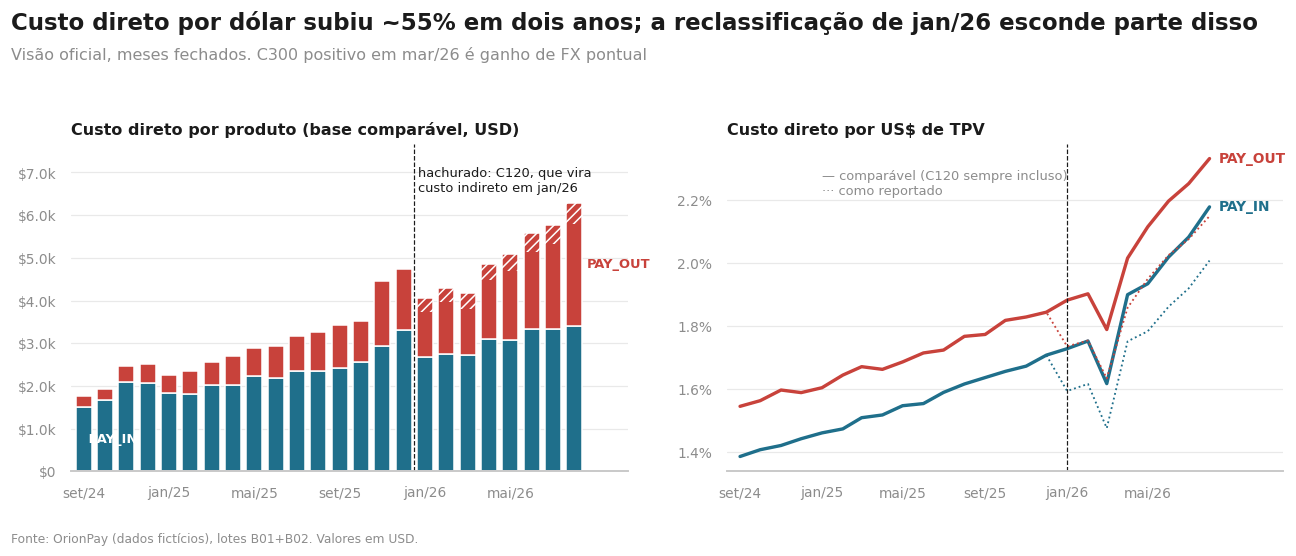

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))

by_product = -direct_by_product["comparavel"][["PAY_IN", "PAY_OUT"]]
reclassified = -costs[(costs["source_account"] == "C120") & (costs["pl_subgroup"] == "INDIRECT_COSTS")].groupby("period")["amount_usd"].sum()
positions = np.arange(len(by_product))
axes[0].bar(positions, by_product["PAY_IN"], color=fn.ACCENT_2, width=0.75)
axes[0].bar(positions, by_product["PAY_OUT"], bottom=by_product["PAY_IN"], color=fn.ACCENT, width=0.75)
reclass_values = reclassified.reindex(by_product.index, fill_value=0)
axes[0].bar(positions, reclass_values, bottom=by_product.sum(axis=1) - reclass_values, facecolor="none", edgecolor="white", hatch="////", width=0.75, lw=0)
axes[0].text(positions[0], by_product.iloc[0, 0] / 2, " PAY_IN", color="white", fontsize=8.5, fontweight="bold", va="center")
axes[0].text(positions[-1] + 0.6, by_product.iloc[-1, 0] + by_product.iloc[-1, 1] / 2, "PAY_OUT", color=fn.ACCENT, fontsize=8.5, fontweight="bold", va="center")
jan_26 = CLOSED.index(pd.Timestamp("2026-01-01"))
axes[0].axvline(jan_26 - 0.5, color=fn.INK, lw=0.8, ls="--")
axes[0].text(jan_26 - 0.3, by_product.sum(axis=1).max() * 1.03, "hachurado: C120, que vira\ncusto indireto em jan/26", fontsize=8.5, color=fn.INK, va="bottom")
axes[0].set_xticks(positions[::4], [fn.format_month(p) for p in CLOSED[::4]])
axes[0].set_xlim(-0.6, len(positions) + 1.5)
axes[0].yaxis.set_major_formatter(fn.usd_formatter(1))
axes[0].set_ylim(0, by_product.sum(axis=1).max() * 1.22)
axes[0].set_title("Custo direto por produto (base comparável, USD)", loc="left", fontsize=10.5, color=fn.INK, fontweight="bold")

for product, color in [("PAY_IN", fn.ACCENT_2), ("PAY_OUT", fn.ACCENT)]:
    axes[1].plot(cost_rate["comparavel"].index, cost_rate["comparavel"][product], color=color, lw=2.2)
    axes[1].plot(cost_rate["como_reportado"].index, cost_rate["como_reportado"][product], color=color, lw=1.2, ls=":")
    fn.label_line_end(axes[1], cost_rate["comparavel"].index[-1], cost_rate["comparavel"][product].iloc[-1], product, color)
axes[1].axvline(pd.Timestamp("2026-01-01"), color=fn.INK, lw=0.8, ls="--")
axes[1].text(pd.Timestamp("2025-01-01"), 0.0222, "— comparável (C120 sempre incluso)\n··· como reportado", fontsize=8.5, color=fn.MUTED)
axes[1].yaxis.set_major_formatter(fn.pct_formatter(1))
axes[1].set_title("Custo direto por US$ de TPV", loc="left", fontsize=10.5, color=fn.INK, fontweight="bold")
axes[1].set_xticks(CLOSED[::4], [fn.format_month(p) for p in CLOSED[::4]])
axes[1].set_xlim(CLOSED[0] - pd.Timedelta(days=20), CLOSED[-1] + pd.Timedelta(days=110))
fn.chart_titles(fig, "Custo direto por dólar subiu ~55% em dois anos; a reclassificação de jan/26 esconde parte disso",
                "Visão oficial, meses fechados. C300 positivo em mar/26 é ganho de FX pontual")
fn.save_chart(fig, "03_custos_diretos")
plt.show()

In [19]:
rule_change = pd.DataFrame(
    {
        "dez/25 como reportado": cost_rate["como_reportado"].loc[pd.Timestamp("2025-12-01")],
        "jan/26 como reportado": cost_rate["como_reportado"].loc[pd.Timestamp("2026-01-01")],
        "dez/25 comparável": cost_rate["comparavel"].loc[pd.Timestamp("2025-12-01")],
        "jan/26 comparável": cost_rate["comparavel"].loc[pd.Timestamp("2026-01-01")],
    }
).T
fn.format_table(rule_change, pct=["PAY_IN", "PAY_OUT"])

product,PAY_IN,PAY_OUT
dez/25 como reportado,1.71%,1.84%
jan/26 como reportado,1.59%,1.74%
dez/25 comparável,1.71%,1.84%
jan/26 comparável,1.73%,1.88%


In [20]:
unattributed_costs = fn.select_view(fact_pnl, "updated")
unattributed_costs = unattributed_costs[(unattributed_costs["product"] == fn.UNATTRIBUTED) & (unattributed_costs["pl_group"] != "NET_REVENUE")]
unattributed_costs.groupby(["source_account", "pl_line", "pl_subgroup", "is_official"])["amount_usd"].agg(["count", "sum"]).round(2)

count      sum
source_account pl_line                     pl_subgroup    is_official                
C190           Additional processing costs DIRECT_COSTS   False            1  -2400.0
C200           Shared service costs        INDIRECT_COSTS False            4   -792.0
                                                          True            96 -27216.0
Z900           Compliance services invoice UNMAPPED       True             6  -3600.0

**Leitura para a pergunta 3**

- **Distribuição**: PAY_IN concentra cerca de 63% do custo direto dos últimos 12 meses (US$ 35,6k de US$ 56,3k). Mas PAY_OUT custa mais por dólar (2,33% contra 2,18% do TPV em ago/26, base comparável) e é o que mais cresce: o custo direto de PAY_OUT triplicou em 12 meses (+212%), contra +50% de PAY_IN, acompanhando o crescimento do volume de cada produto.
- **Evolução**: na base comparável, o custo direto por US$ de TPV subiu de 1,39% para 2,18% em PAY_IN e de 1,55% para 2,33% em PAY_OUT entre set/24 e ago/26 (cerca de +55%). Processing costs (C100) é a maior linha, cerca de 70% do custo direto.
- **Comparabilidade**: a série **não é comparável como reportada**. Em jan/26 a conta C120 (Platform costs) passa de DIRECT para INDIRECT. O custo direto reportado cai ~0,13 p.p. do TPV de uma vez, sem mudança econômica. O GP não muda, porque as duas classes estão em Cost of Sales. Para comparar no tempo é preciso usar a base comparável (C120 sempre dentro), e é ela que está no gráfico.
- **Sem atribuição a produto**: C190 (-US$ 2,4k em ago/26, só na visão atualizada, postado depois do cutoff) é custo direto sem produto nem merchant. Shared services (C200) e Z900 também não têm produto, mas não são custos diretos.
- **Pontual**: C300 (resultado de FX) é positivo em todos os 123 lançamentos de mar/26 (+US$ 374), contra cerca de -US$ 125/mês no resto da série. A regra permite custo positivo, então foi mantido, mas distorce o custo direto do mês.

---
## Pergunta 4 · TPV e GP de jan–set: 2026 contra 2025

Jan–ago são meses fechados (visão oficial). **Set/26 está aberto e só vai até 20/09**, então set é comparado *like-for-like* (dias 1 a 20 nos dois anos). No GP de setembro entram só as linhas transacionais: C300 e C200 são lançados no fim do mês em 2025 e de forma parcial em 2026, o que tornaria a comparação enviesada.

In [21]:
TRANSACTIONAL_ACCOUNTS = ["R100", "R110", "R190", "C100", "C110", "C120"]
entries_silver = pd.read_csv(fn.SILVER_DIR / "financial_entries.csv", parse_dates=["accounting_date"])

def september_to_day_20(year: int) -> pd.Series:
    start, end = pd.Timestamp(f"{year}-09-01"), pd.Timestamp(f"{year}-09-20 23:59:59")
    tpv = payments[(payments["event_at"].dt.tz_localize(None) >= start) & (payments["event_at"].dt.tz_localize(None) <= end)]["amount_usd"].sum()
    window = entries_silver[(entries_silver["accounting_date"] >= start) & (entries_silver["accounting_date"] <= end)]
    gp = window[window["source_account"].isin(TRANSACTIONAL_ACCOUNTS)]["amount_usd"].sum()
    return pd.Series({"tpv": tpv, "gross_profit": gp})

yoy_months = pd.DataFrame(
    {
        year: monthly.loc[[pd.Timestamp(f"{year}-{m:02d}-01") for m in range(1, 9)], ["tpv", "gross_profit"]].set_axis(range(1, 9)).stack()
        for year in (2025, 2026)
    }
).unstack()
for year in (2025, 2026):
    for metric, value in september_to_day_20(year).items():
        yoy_months.loc[9, (year, metric)] = value

yoy = pd.DataFrame(
    {
        "jan–ago 2025": yoy_months.loc[1:8].xs(2025, axis=1, level=0).sum(),
        "jan–ago 2026": yoy_months.loc[1:8].xs(2026, axis=1, level=0).sum(),
        "set 1–20 2025": yoy_months.loc[9].xs(2025),
        "set 1–20 2026": yoy_months.loc[9].xs(2026),
    }
).T
yoy.loc["jan–set* 2025"] = yoy.loc[["jan–ago 2025", "set 1–20 2025"]].sum()
yoy.loc["jan–set* 2026"] = yoy.loc[["jan–ago 2026", "set 1–20 2026"]].sum()
growth = pd.DataFrame(
    {
        "jan–ago": yoy.loc["jan–ago 2026"] / yoy.loc["jan–ago 2025"] - 1,
        "set 1–20": yoy.loc["set 1–20 2026"] / yoy.loc["set 1–20 2025"] - 1,
        "jan–set*": yoy.loc["jan–set* 2026"] / yoy.loc["jan–set* 2025"] - 1,
    }
).T
display(fn.format_table(yoy, usd=["tpv", "gross_profit"]))
fn.format_table(growth, pct=["tpv", "gross_profit"])

,tpv,gross_profit
jan–ago 2025,"$1,409,333","$17,546"
jan–ago 2026,"$2,036,447","$11,495"
set 1–20 2025,"$133,691","$2,186"
set 1–20 2026,"$192,033",$980
jan–set* 2025,"$1,543,024","$19,732"
jan–set* 2026,"$2,228,480","$12,475"


,tpv,gross_profit
jan–ago,44.50%,-34.49%
set 1–20,43.64%,-55.15%
jan–set*,44.42%,-36.77%


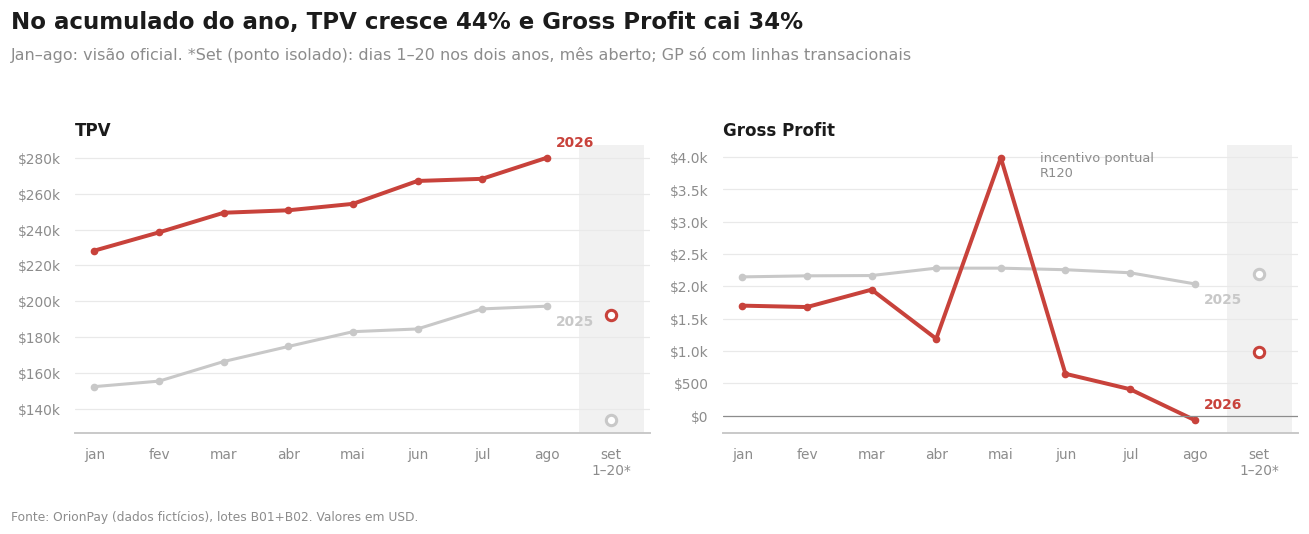

In [22]:
month_labels = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set\n1–20*"]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, metric, title, decimals in [(axes[0], "tpv", "TPV", 0), (axes[1], "gross_profit", "Gross Profit", 1)]:
    for year, color, width in [(2025, fn.NEUTRAL, 2.0), (2026, fn.ACCENT, 2.6)]:
        series = yoy_months[(year, metric)]
        ax.plot(range(1, 9), series.loc[1:8].values, color=color, lw=width, marker="o", ms=4)
        ax.scatter([9], [series.loc[9]], s=46, facecolor="white", edgecolor=color, lw=2, zorder=3)
        fn.label_line_end(ax, 8, series.loc[8], str(year), color, offset=10 if year == 2026 else -10)
    ax.axvspan(8.5, 9.5, color=fn.GRID, alpha=0.6, lw=0)
    ax.set_xticks(range(1, 10), month_labels)
    ax.set_xlim(0.7, 9.6)
    ax.yaxis.set_major_formatter(fn.usd_formatter(decimals))
    ax.set_title(title, loc="left", fontsize=11, color=fn.INK, fontweight="bold")
axes[1].axhline(0, color=fn.MUTED, lw=0.8)
axes[1].annotate("incentivo pontual\nR120", xy=(5, yoy_months.loc[5, (2026, "gross_profit")]), xytext=(5.6, 3700), fontsize=8.5, color=fn.MUTED)
fn.chart_titles(fig, "No acumulado do ano, TPV cresce 44% e Gross Profit cai 34%",
                "Jan–ago: visão oficial. *Set (ponto isolado): dias 1–20 nos dois anos, mês aberto; GP só com linhas transacionais")
fn.save_chart(fig, "04_yoy_jan_set")
plt.show()

**Leitura para a pergunta 4**

- **TPV**: +44,5% em jan–ago/26 contra jan–ago/25 (US$ 2,04M contra US$ 1,41M), e o ritmo se mantém em setembro (+43,6% nos dias 1–20). O crescimento é puxado pelo Brasil e por PAY_OUT.
- **Gross Profit**: -34,5% em jan–ago (US$ 11,5k contra US$ 17,5k), mesmo incluindo o incentivo pontual de mai/26 (US$ 3,0k). Sem ele, a queda seria de 52%. Em todos os meses de 2026 o GP fica abaixo de 2025, exceto em maio (pelo incentivo), e a distância cresce a partir de jun. Em set (1–20), o GP das linhas transacionais cai 55%.
- **Ressalvas**: 2025 já usa o câmbio corrigido de mar/25 (sem a correção, a comparação de março mostraria queda de TPV de 40%). Set/26 é parcial e sem fechamento oficial. Z900 (compliance, -US$ 3,6k em jun–ago/26) está fora do GP: se for classificada como custo de venda, a queda em 2026 seria ainda maior.

---
## Pergunta 5 · O que mudou com B02?

In [23]:
b02_events = fact_tpv[fact_tpv["batch_id"] == "B02"].groupby("period")[["payments", "tpv_usd"]].sum()
b02_entries = fact_pnl[fact_pnl["batch_id"] == "B02"].groupby(["period", "source_account", "pl_line", "is_official", "is_late_posting"])[["entries", "amount_usd"]].sum()
display(b02_events.rename(index=fn.format_month))
b02_entries

,payments,tpv_usd
period,,
set/26,152,48681.99


entries  amount_usd
period     source_account pl_line                     is_official is_late_posting                     
2026-08-01 C190           Additional processing costs False       True                   1    -2400.00
2026-09-01 C100           Processing costs            False       False                152     -799.33
           C110           Network costs               False       False                152     -222.08
           C120           Platform costs              False       False                152      -88.86
           C300           FX settlement result        False       False                 63      -24.36
           R100           Processing fees             False       False                152     1226.45
           R110           Service fees                False       False                152       97.40
           R190           Fee credits                 False       False                  2       -4.27

In [24]:
views = {
    "Oficial B01": fn.pnl_summary(fact_pnl, fact_tpv, ["period"], view="official", batches=("B01",)),
    "Oficial B01+B02": fn.pnl_summary(fact_pnl, fact_tpv, ["period"], view="official"),
    "Atualizada B01": fn.pnl_summary(fact_pnl, fact_tpv, ["period"], view="updated", batches=("B01",)),
    "Atualizada B01+B02": monthly_updated,
}
rows = []
for name, frame in views.items():
    for period in [LAST_CLOSED, OPEN_PERIOD]:
        if period in frame.index and not (name.startswith("Oficial") and period == OPEN_PERIOD):
            rows.append({"visão": name, "mês": fn.format_month(period), **frame.loc[period, ["tpv", "net_revenue", "cost_of_sales", "gross_profit"]].to_dict()})
comparison = pd.DataFrame(rows).set_index(["mês", "visão"]).sort_index()
fn.format_table(comparison, usd=["tpv", "net_revenue", "cost_of_sales", "gross_profit"])

Maior diferença de GP oficial em meses fechados entre B01 e B01+B02: US$ 0.00


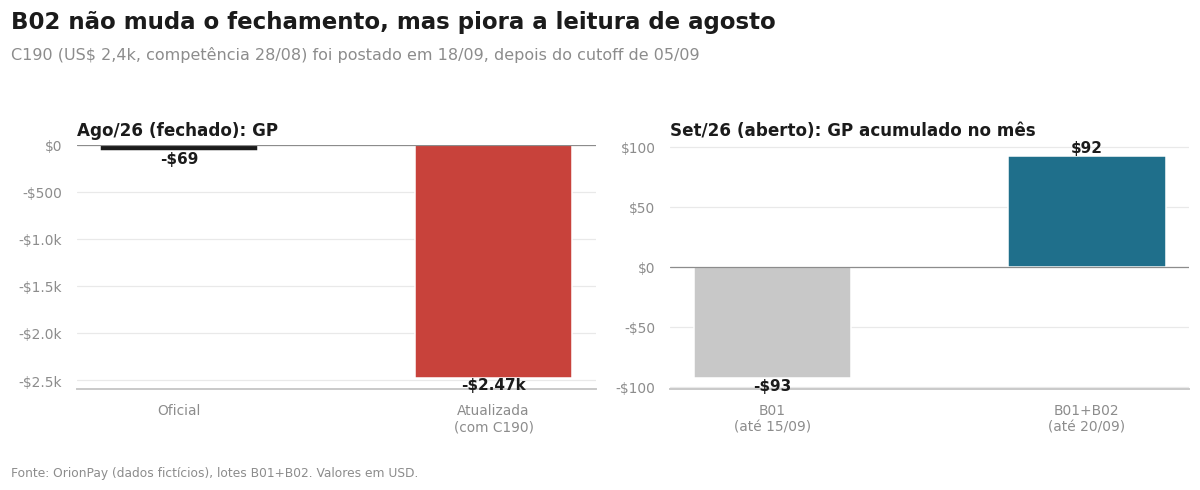

In [25]:
closed_change = (views["Oficial B01+B02"].loc[CLOSED, "gross_profit"] - views["Oficial B01"].loc[CLOSED, "gross_profit"]).abs().max()
print(f"Maior diferença de GP oficial em meses fechados entre B01 e B01+B02: US$ {closed_change:,.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
aug_values = pd.Series({"Oficial": views["Oficial B01+B02"].loc[LAST_CLOSED, "gross_profit"], "Atualizada\n(com C190)": views["Atualizada B01+B02"].loc[LAST_CLOSED, "gross_profit"]})
sep_values = pd.Series({"B01\n(até 15/09)": views["Atualizada B01"].loc[OPEN_PERIOD, "gross_profit"], "B01+B02\n(até 20/09)": views["Atualizada B01+B02"].loc[OPEN_PERIOD, "gross_profit"]})
for ax, values, title, colors in [
    (axes[0], aug_values, "Ago/26 (fechado): GP", [fn.INK, fn.ACCENT]),
    (axes[1], sep_values, "Set/26 (aberto): GP acumulado no mês", [fn.NEUTRAL, fn.ACCENT_2]),
]:
    ax.bar(values.index, values.values, color=colors, width=0.5)
    for i, v in enumerate(values):
        ax.text(i, v, fn.format_usd(v, 2), ha="center", va="bottom" if v >= 0 else "top", fontsize=10, color=fn.INK, fontweight="bold")
    ax.axhline(0, color=fn.MUTED, lw=0.8)
    ax.yaxis.set_major_formatter(fn.usd_formatter(1))
    ax.set_title(title, loc="left", fontsize=11, color=fn.INK, fontweight="bold")
fn.chart_titles(fig, "B02 não muda o fechamento, mas piora a leitura de agosto",
                "C190 (US$ 2,4k, competência 28/08) foi postado em 18/09, depois do cutoff de 05/09")
fn.save_chart(fig, "05_impacto_b02")
plt.show()

**Leitura para a pergunta 5**

**O que o B02 trouxe**: 162 eventos de 16 a 20/09 (152 capturas confirmadas, +US$ 48,7k de TPV em set/26) e 826 lançamentos. 825 são de setembro (taxas e custos dos novos pagamentos, 63 resultados de FX parciais e 2 fee credits). 1 é de agosto: uma fatura de processing services (C190, -US$ 2,4k, Brasil, sem merchant), com competência 28/08 e postada em 18/09.

**A visão oficial deve mudar? Não.** O C190 chegou depois do cutoff de agosto (05/09), então pela regra fica fora do fechamento oficial. Nenhum número oficial de set/24 a ago/26 muda com B02 (diferença máxima: US$ 0,00).

**O que publicar**

| Número | Visão | Status |
|---|---|---|
| P&L set/24–ago/26 (ago/26: GP -US$ 69) | Oficial | **Publicar** para Finance |
| GP ago/26 atualizado: -US$ 2.469 | Atualizada | **Publicar com ressalva** na leitura de performance: inclui fatura pós-cutoff |
| Set/26 parcial (TPV US$ 192k, GP US$ 92 até 20/09) | Atualizada | **Ressalva forte**: mês aberto, accruals parciais, sem fechamento. Com B02 o GP do mês passa de -US$ 93 para +US$ 92 |
| GP excluindo Z900 | Ambas | **Ressalva**: compliance de US$ 1,2k/mês sem classificação |
| GP de mai/26 | Oficial | **Ressalva**: 75% é incentivo pontual com sinal a confirmar |

**Ações recomendadas (priorizadas)**

1. **Rever o pricing do Brasil e de PAY_OUT (impacto alto, recorrente).** *Evidência*: o Brasil tem 74% do TPV e GP/TPV negativo; o take rate brasileiro caiu de 3,13% para 2,44% enquanto o custo direto por TPV subiu. O efeito preço explica ~2/3 da queda do take rate total. *Limitação*: não temos o contrato por merchant nem o custo de aquisição, então parte da queda de preço pode ser estratégia deliberada de ganho de share.
2. **Fechar a governança contábil (impacto alto na confiabilidade).** Mapear a Z900 no `account_mapping`, confirmar o sinal do R120 e corrigir a taxa COP de mar/25 na fonte. Junto disso, criar controle de cutoff para faturas de fornecedor (o C190 chegou quase duas semanas depois do cutoff) e checagem de unicidade de `entry_id` na ingestão (427 duplicados em jul/26). *Evidência*: log DQ01–DQ05. *Limitação*: as correções de Z900 e R120 dependem de confirmação de Finance; até lá, ficam como ressalva.
3. **Atacar o custo de processamento (C100) e o shared services (C200).** O C100 é a maior linha e cresce mais rápido que o TPV, e o C200 cresce ~3% ao mês desacoplado do volume. Vale renegociar com o processador e rever o rateio de shared services. *Limitação*: não temos o detalhe de fornecedor por trás do C100.